# Welcome To Learning PySpark

### DataFrame

DataFrame is two dimensional data structure

1️⃣ What is a DataFrame?

✅ Definition:
A DataFrame in PySpark is a distributed, immutable collection of data organized in rows and columns (like a SQL table or Pandas DataFrame).

✅ Key Features:

Supports structured and semi-structured data.

Schema-based: Has column names and data types.

Optimized for big data processing using Spark’s distributed computing.

Supports SQL-like queries and transformations.

## Q. Diff between DataFrame and RDD


## SparkSession

In [1]:
pip install pyspark

In [2]:
import pyspark

In [3]:
from pyspark.sql import SparkSession

In [4]:
spark = SparkSession.builder.appName('Learning Pyspark').getOrCreate()
# spark = SparkSession.builder.getOrCreate()
# spark = pyspark.sql.SparkSession.builder.getOrCreate()
# spark = ps.sql.SparkSession.builder.getOrCreate()

In [ ]:
SparkSession---> DataFrame and RDD
SparkContext---> RDD

## Create DataFrame

In [ ]:
data = [(1,'Rohit','BE','Mumbai',10000),
        (2, 'Anurag','BE','Pune',15000),
        (3,'Mukul','BTECH','Pune', 20000),
        (2, 'Anurag','BE','Pune',15000),
        (4, 'Priyanka','MBA', 'Nagpur', 25000)]

In [ ]:
columns = ['Id','Name','Graduation','City','Salary']

In [ ]:
df = spark.createDataFrame(data, columns)

In [ ]:
df.show()

+---+--------+----------+------+------+
| Id|    Name|Graduation|  City|Salary|
+---+--------+----------+------+------+
|  1|   Rohit|        BE|Mumbai| 10000|
|  2|  Anurag|        BE|  Pune| 15000|
|  3|   Mukul|     BTECH|  Pune| 20000|
|  2|  Anurag|        BE|  Pune| 15000|
|  4|Priyanka|       MBA|Nagpur| 25000|
+---+--------+----------+------+------+



In [ ]:
# syntax
df.select('Name').show()

+--------+
|    Name|
+--------+
|   Rohit|
|  Anurag|
|   Mukul|
|  Anurag|
|Priyanka|
+--------+



In [ ]:
# synatx
df.select('Name','City').show()

+--------+------+
|    Name|  City|
+--------+------+
|   Rohit|Mumbai|
|  Anurag|  Pune|
|   Mukul|  Pune|
|  Anurag|  Pune|
|Priyanka|Nagpur|
+--------+------+



In [ ]:
df = spark.read.csv('/content/employee_data_with_duplicates.csv', header=True)

In [ ]:
df.show()

+-----------+-----+---+----------+------+
|employee_id| name|age|department|salary|
+-----------+-----+---+----------+------+
|        101|Ankit| 28|        IT| 50000|
|        102|Priya| 30|        HR| 52000|
|        103| Ravi| 32|   Finance| 58000|
|        104|Meena| 29|        IT| 51000|
|        101|Ankit| 28|        IT| 50000|
|        102|Priya| 30|        HR| 52000|
|        105|Karan| 31| Marketing| 54000|
|        106| Neha| 27|   Finance| 50000|
|        103| Ravi| 32|   Finance| 58000|
+-----------+-----+---+----------+------+



In [ ]:
df2 = df.dropDuplicates()

In [ ]:
df2.show()

+-----------+-----+---+----------+------+
|employee_id| name|age|department|salary|
+-----------+-----+---+----------+------+
|        105|Karan| 31| Marketing| 54000|
|        106| Neha| 27|   Finance| 50000|
|        102|Priya| 30|        HR| 52000|
|        103| Ravi| 32|   Finance| 58000|
|        104|Meena| 29|        IT| 51000|
|        101|Ankit| 28|        IT| 50000|
+-----------+-----+---+----------+------+



In [ ]:
df = pd.read_csv('file_path')

In [ ]:
df = spark.read.csv('/content/input_data.csv', header=True)
df.show()

+-------+-------+-------+--------------+--------+------------+---------------+
|column1|column2|column3|       column4|  salary|joining_date|     department|
+-------+-------+-------+--------------+--------+------------+---------------+
|      1|      A|   60.0|     John@Doe!|120000.0|  2023-01-15|    Engineering|
|      2|      B|   45.0|   Jane*Smith^| 90000.0|  2022-12-10|      Marketing|
|      3|      A|   70.0|Robert_Johnson|110000.0|  2021-11-20|    Engineering|
|      4|      C|   55.0|  Emily$Clark%|    NULL|  2020-07-30|Human Resources|
|      5|      D|   NULL|Michael#Brown!| 95000.0|  2019-05-22|        Finance|
|      6|      E|   80.0|  Laura&&Davis|105000.0|  2018-09-10|    Engineering|
|      7|      B|   45.0|   Jane*Smith^| 90000.0|  2022-12-10|      Marketing|
+-------+-------+-------+--------------+--------+------------+---------------+



## RDD
RDD is fundamental data structure of spark

Resilinet Distributed Dataset
- fault tolarant
- Immutable

Q: How can you create an RDD in Spark?

A: You can create an RDD in Spark by parallelizing an existing collection in your driver program using the sc.parallelize() method, or by reading data from an external data source such as a text file, HDFS, or a database using SparkContext's textFile(), hadoopFile(), or jdbcRDD() methods respectively.

In [5]:
data = [1,2,3,4,5]

In [6]:
rdd1 = spark.sparkContext.parallelize(data)

In [7]:
rdd1.collect()

[1, 2, 3, 4, 5]

## Actions

Collect()
Count()
take()
tail()
Head()
Describe()
Columns()

In [8]:
data = [('Amruta','BE','Pune', 50000), ('Puja','BE','Vadodara',60000),
 ('Shilpa','BSC','Mumbai', 55000), ('Aarti','MSC','Chennai', 70000),('Pranay','BTECH','Hyderabad',60000)]

In [9]:
columns = ['Name','Education','City','Salary']

In [10]:
spark_df = spark.createDataFrame(data, columns)

In [11]:
spark_df.show()

+------+---------+---------+------+
|  Name|Education|     City|Salary|
+------+---------+---------+------+
|Amruta|       BE|     Pune| 50000|
|  Puja|       BE| Vadodara| 60000|
|Shilpa|      BSC|   Mumbai| 55000|
| Aarti|      MSC|  Chennai| 70000|
|Pranay|    BTECH|Hyderabad| 60000|
+------+---------+---------+------+



In [12]:
spark_df.printSchema()

root
 |-- Name: string (nullable = true)
 |-- Education: string (nullable = true)
 |-- City: string (nullable = true)
 |-- Salary: long (nullable = true)



In [14]:
spark_df.head(3)

[Row(Name='Amruta', Education='BE', City='Pune', Salary=50000),
 Row(Name='Puja', Education='BE', City='Vadodara', Salary=60000),
 Row(Name='Shilpa', Education='BSC', City='Mumbai', Salary=55000)]

In [15]:
spark_df.describe()

DataFrame[summary: string, Name: string, Education: string, City: string, Salary: string]

In [16]:
spark_df.columns

['Name', 'Education', 'City', 'Salary']

In [ ]:
# how to convert spark df into pandas df

pandas_df = spark_df.toPandas()

In [ ]:
# convert pandas df into spark df
spark_df2 = spark.createDataFrame(pandas_df)

In [ ]:
from pyspark import SparkContext
sc = SparkContext.getOrCreate()

#spark.sparkContext.parallelize(data)

In [ ]:
my_rdd = sc.parallelize([1,2,3,4,5])

## create empty rdd

In [ ]:

from pyspark.sql import SparkSession
spark = SparkSession.builder.appName('SparkByExamples.com').getOrCreate()

#Creates Empty RDD
emptyRDD = spark.sparkContext.emptyRDD()
print(emptyRDD)

#Diplays
#EmptyRDD[188] at emptyRDD


In [ ]:

#Creates Empty RDD using parallelize
rdd2= spark.sparkContext.parallelize([])
print(rdd2)

#EmptyRDD[205] at emptyRDD at NativeMethodAccessorImpl.java:0
#ParallelCollectionRDD[206] at readRDDFromFile at PythonRDD.scala:262


### What is a Transformation in Spark?
A transformation is an operation that creates a new RDD or DataFrame from an existing one.
It is a lazy operation – Spark does not execute it immediately.
Examples: map(), filter(), flatMap(), groupBy(), select() (for DataFrames)


### What is an Action in Spark?
An action is an operation that triggers the execution of transformations and returns a result or writes data.
Actions force Spark to execute the DAG and get the final output.
Examples: collect(), count(), take(), show(), saveAsTextFile()


### What is Lazy Evaluation in Spark?
Spark delays the execution of transformations until an action is called.
It builds a DAG (Directed Acyclic Graph) of transformations.
This allows Spark to optimize the execution plan before actually running tasks.


# RDD Actions

In [17]:
from pyspark import SparkContext

In [18]:
sc = SparkContext.getOrCreate()

In [19]:
rdd1 = sc.parallelize([1,2,3,4,5])

In [20]:
rdd1.collect()

[1, 2, 3, 4, 5]

In [ ]:
rdd1.sum()

15

In [ ]:
rdd1.min()

1

In [ ]:
rdd1.max()

5

In [ ]:
rdd1.mean()

3.0

In [ ]:
rdd1.count()

5

In [21]:
rdd1.take(3)

[1, 2, 3]

In [26]:
rdd1.top(2)

[5, 4]

In [29]:
rdd1.head()  # will not work
rdd1.tail() # will not work

AttributeError: 'RDD' object has no attribute 'head'

In [ ]:
rdd1.collect()

[1, 2, 3, 4, 5]

### map

In [ ]:
map = rdd1.map(lambda x : x + 2)

In [ ]:
map.collect()

[3, 4, 5, 6, 7]

### filter

In [ ]:
filter_rdd = rdd1.filter(lambda x: x%2 == 0)

In [ ]:
filter_rdd.collect()

[2, 4]

# Understanding map() and flatMap() in PySpark RDDs

map() and flatMap() are fundamental RDD transformations in PySpark.

These functions help process and transform data efficiently.

### 1️⃣ What is map() in PySpark?

map() applies a function to each element of an RDD and returns a new RDD with transformed elements.

Each input element produces one output element.

In [ ]:
# Example: Converting words to uppercase
rdd = spark.sparkContext.parallelize(["apple", "banana", "grape"])
rdd.collect()
print(rdd.collect())

['apple', 'banana', 'grape']


In [ ]:
mapped_rdd = rdd.map(lambda x: x.upper())
print(mapped_rdd.collect())

['APPLE', 'BANANA', 'GRAPE']


Each element gets transformed one-to-one.

### 2️⃣ What is flatMap() in PySpark?

flatMap() is similar to map(), but each input element can produce multiple output elements.

It is commonly used when dealing with lists, sentences, or nested structures.

In [ ]:
# Example: Splitting sentences into words

rdd = spark.sparkContext.parallelize(["hello world", "pyspark rdd"])
print(rdd.collect())


['hello world', 'pyspark rdd']


In [ ]:
flat_mapped_rdd = rdd.flatMap(lambda x: x.split(" "))
print(flat_mapped_rdd.collect())

['hello', 'world', 'pyspark', 'rdd']


Unlike map(), which would return [["hello", "world"], ["pyspark", "rdd"]], flatMap() flattens the output.

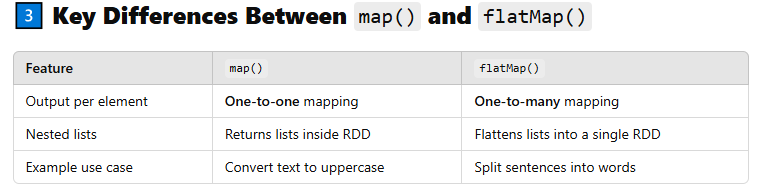

In [ ]:
rdd = spark.sparkContext.parallelize(["a b", "c d"])
print(rdd.collect())

['a b', 'c d']


In [ ]:
print(rdd.map(lambda x: x.split()).collect())

[['a', 'b'], ['c', 'd']]


In [ ]:
print(rdd.flatMap(lambda x: x.split()).collect())

['a', 'b', 'c', 'd']


4️⃣ When to Use map() vs flatMap()?

✅ Use map() when you want one-to-one transformation

✅ Use flatMap() when you need to flatten nested structures or work with lists

# Using map() vs flatMap() in PySpark DataFrames

In PySpark, map() and flatMap() are RDD-level transformations. However, DataFrames operate differently.

Instead of map() and flatMap(), we use select(), explode(), and other DataFrame transformations.



### 1️⃣ Using map() with DataFrames
Since DataFrames are not RDDs, we cannot use map() directly.

However, we can use rdd.map() to convert a DataFrame to an RDD, apply transformations, and convert it back.

In [ ]:
# Example: Converting names to uppercase
from pyspark.sql import SparkSession

# Create Spark Session
spark = SparkSession.builder.appName("MapExample").getOrCreate()

In [ ]:
# Create DataFrame
data = [("Amit", 28), ("Priya", 32), ("Ravi", 25)]

df = spark.createDataFrame(data, ["name", "age"])
df.show()

+-----+---+
| name|age|
+-----+---+
| Amit| 28|
|Priya| 32|
| Ravi| 25|
+-----+---+



In [ ]:
# Apply map() on RDD
mapped_rdd = df.rdd.map(lambda row: (row.name.upper(), row.age))

# Convert RDD back to DataFrame
mapped_df = mapped_rdd.toDF(["name", "age"])

mapped_df.show()

+-----+---+
| name|age|
+-----+---+
| AMIT| 28|
|PRIYA| 32|
| RAVI| 25|
+-----+---+



map() is used at the RDD level, then converted back to DataFrame

### 2️⃣ Using flatMap() with DataFrames

In DataFrames, explode() is used instead of flatMap().

It helps split array-type columns into multiple rows.

In [ ]:
# Example: Flattening a list of favorite cities

In [ ]:
from pyspark.sql.functions import explode

# Create DataFrame with an array column
data = [("Amit", ["Mumbai", "Delhi"]),
        ("Priya", ["Bangalore", "Chennai"]),
        ("Ravi", ["Hyderabad"])]

df = spark.createDataFrame(data, ["name", "cities"])
df.show()

+-----+--------------------+
| name|              cities|
+-----+--------------------+
| Amit|     [Mumbai, Delhi]|
|Priya|[Bangalore, Chennai]|
| Ravi|         [Hyderabad]|
+-----+--------------------+



In [ ]:
# Use explode() to flatten the city list
flattened_df = df.withColumn("city", explode(df.cities)).drop("cities")

flattened_df.show()

+-----+---------+
| name|     city|
+-----+---------+
| Amit|   Mumbai|
| Amit|    Delhi|
|Priya|Bangalore|
|Priya|  Chennai|
| Ravi|Hyderabad|
+-----+---------+



### Example_2: Exploding a List of Mobile Numbers for Customers

Scenario:

Suppose we have customer data where each customer has multiple registered mobile numbers. We want to normalize the data by exploding the mobile numbers into separate rows.

In [ ]:
from pyspark.sql.functions import explode

# Sample Data (Customers with Multiple Mobile Numbers)
data = [
    ("Amit", ["+91-9876543210", "+91-9123456789"]),
    ("Priya", ["+91-8765432109"]),
    ("Ravi", ["+91-9988776655", "+91-8877665544", "+91-7766554433"])
]

# Create DataFrame
df = spark.createDataFrame(data, ["name", "mobile_numbers"])
df.show()
df.show(truncate=False)

+-----+--------------------+
| name|      mobile_numbers|
+-----+--------------------+
| Amit|[+91-9876543210, ...|
|Priya|    [+91-8765432109]|
| Ravi|[+91-9988776655, ...|
+-----+--------------------+

+-----+------------------------------------------------+
|name |mobile_numbers                                  |
+-----+------------------------------------------------+
|Amit |[+91-9876543210, +91-9123456789]                |
|Priya|[+91-8765432109]                                |
|Ravi |[+91-9988776655, +91-8877665544, +91-7766554433]|
+-----+------------------------------------------------+



In [ ]:
# Use explode() to normalize the mobile numbers
flattened_df = df.withColumn("mobile", explode(df.mobile_numbers)).drop("mobile_numbers")

# Show Result
flattened_df.show()

+-----+--------------+
| name|        mobile|
+-----+--------------+
| Amit|+91-9876543210|
| Amit|+91-9123456789|
|Priya|+91-8765432109|
| Ravi|+91-9988776655|
| Ravi|+91-8877665544|
| Ravi|+91-7766554433|
+-----+--------------+



explode() works like flatMap() by creating multiple rows from a single list.



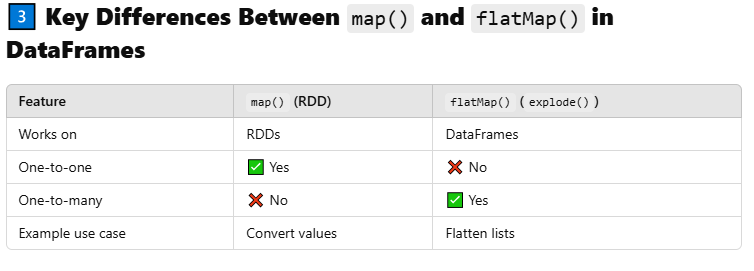

### 4️⃣ When to Use map() vs explode() in DataFrames?

✅ Use map() when you want row-wise transformations

✅ Use explode() when dealing with lists or nested structures